In [64]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [65]:
# 한글 깨짐 방지 위해 구글 코랩에 나눔폰트 설치.
import sys
if 'google.colab' in sys.modules:
    !echo 'debconf debconf/frontend select Noninteractive' | debconf-set-selections
    !sudo apt-get -qq -y install fonts-nanum
    import matplotlib.font_manager as fm
    font_files = fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum'])
    for fpath in font_files:
        fm.fontManager.addfont(fpath)

# 필요한 라이브러리

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.preprocessing import StandardScaler, MinMaxScaler

from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error as mse
from sklearn.metrics import r2_score, mean_squared_error, r2_score, mean_absolute_error
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score as acc
from sklearn.metrics import recall_score as recall

import joblib

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [67]:
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

# 필요한 함수

In [68]:
def vif(dataframe, features):
    """
    다중공선성(VIF)을 계산하는 함수 (const 자동 제거)

    Parameters:
    - dataframe: pd.DataFrame
        입력 데이터프레임
    - features: list of str
        독립 변수(컬럼명) 리스트

    Returns:
    - vif_df: pd.DataFrame
        독립 변수들과 해당하는 VIF 값을 담은 데이터프레임
        (const는 포함되지 않음)
    """
    X = dataframe[features]
    X_const = add_constant(X)

    vif_data = pd.DataFrame()
    vif_data["변수"] = X_const.columns
    vif_data["VIF"] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]

    # const 행 제거
    vif_data = vif_data[vif_data["변수"] != "const"]

    return vif_data

In [69]:
import statsmodels.api as sm
import pandas as pd
import matplotlib.pyplot as plt
import warnings

def stepwise_feature_selection(X_train, y_train, variables=None, sl_enter=0.05, sl_remove=0.05):
    """
    전진 선택 + 후진 제거를 통한 변수 선택

    Parameters:
    - X_train: pd.DataFrame
    - y_train: pd.Series 또는 np.array
    - variables: 선택에 사용할 변수 리스트 (기본: X_train.columns)
    - sl_enter: 포함 기준 p-value
    - sl_remove: 제거 기준 p-value

    Returns:
    - selected_variables: 최종 선택된 변수 리스트
    """
    warnings.filterwarnings("ignore")

    if variables is None:
        variables = X_train.columns.tolist()

    y = y_train.copy()
    selected_variables = []
    steps = []
    sv_per_step = []
    adjusted_r_squared = []
    step = 0

    while len(variables) > 0:
        remainder = list(set(variables) - set(selected_variables))
        pval = pd.Series(index=remainder, dtype=float)

        # 전진 선택
        for col in remainder:
            X = sm.add_constant(X_train[selected_variables + [col]])
            model = sm.OLS(y, X).fit()
            pval[col] = model.pvalues[col]

        min_pval = pval.min()

        if min_pval < sl_enter:
            best_var = pval.idxmin()
            selected_variables.append(best_var)

            # 후진 제거
            while len(selected_variables) > 0:
                X_selected = sm.add_constant(X_train[selected_variables])
                model = sm.OLS(y, X_selected).fit()
                selected_pvals = model.pvalues.drop('const')

                max_pval = selected_pvals.max()
                if max_pval >= sl_remove:
                    worst_var = selected_pvals.idxmax()
                    selected_variables.remove(worst_var)
                else:
                    break

            # 결과 저장
            step += 1
            steps.append(step)
            sv_per_step.append(selected_variables.copy())
            adj_r2 = sm.OLS(y, sm.add_constant(X_train[selected_variables])).fit().rsquared_adj
            adjusted_r_squared.append(adj_r2)

        else:
            break

    # 그래프 출력
    plt.figure(figsize=(12, 6))
    plt.xticks(steps, [f'Step {s}\n' + '\n'.join(sv) for s, sv in zip(steps, sv_per_step)], fontsize=10)
    plt.plot(steps, adjusted_r_squared, marker='o', color='blue')
    plt.ylabel('Adjusted R Squared', fontsize=12)
    plt.xlabel('Step', fontsize=12)
    plt.title('단계별 선택법 과정', fontsize=14)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return selected_variables

# 데이터 불러오기

In [70]:
# 'air_2021.csv'파일을 'air_21' 변수에, 'air_2022.csv'파일을 'air_22' 변수에 저장
df_21 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/11주차/df_21_v2.csv')
df_22 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/11주차/df_22_v2.csv')

In [71]:
df_21.head(3)

,time,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),풍속(m/s),...,중하층운량(10분위),최저운고(100m ),시정(10m),지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C),PM_lag1,PM10_1
0,2021-01-01 01:00:00,0.002,0.5,0.022,0.016,24.0,14.0,-8.7,0.0,2.4,...,0,0.0,2000,-6.9,-1.0,-0.8,0.3,1.6,11.0,25.0
1,2021-01-01 02:00:00,0.002,0.6,0.018,0.020,25.0,14.0,-9.1,0.0,1.6,...,0,0.0,2000,-7.1,-1.1,-0.8,0.3,1.6,27.0,27.0
2,2021-01-01 03:00:00,0.002,0.6,0.013,0.025,27.0,16.0,-9.3,0.0,1.1,...,0,0.0,2000,-7.3,-1.2,-0.9,0.3,1.6,17.0,23.0


In [72]:
df_21 = df_21.drop(['time', 'PM_lag1'], axis=1)
df_22 = df_22.drop(['time', 'PM_lag1'], axis=1)

In [73]:
df_21['PM10_1'] = df_21['PM10'].shift(-1)

In [74]:
df_22['PM10_1'] = df_22['PM10'].shift(-1)

In [75]:
df_21 = df_21.dropna()
df_22 = df_22.dropna()

In [76]:
df_21

,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),풍속(m/s),풍향(16방위),...,전운량(10분위),중하층운량(10분위),최저운고(100m ),시정(10m),지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C),PM10_1
0,0.002,0.5,0.022,0.016,24.0,14.0,-8.7,0.0,2.4,270.0,...,0.0,0,0.0,2000,-6.9,-1.0,-0.8,0.3,1.6,25.0
1,0.002,0.6,0.018,0.020,25.0,14.0,-9.1,0.0,1.6,270.0,...,0.0,0,0.0,2000,-7.1,-1.1,-0.8,0.3,1.6,27.0
2,0.002,0.6,0.013,0.025,27.0,16.0,-9.3,0.0,1.1,250.0,...,0.0,0,0.0,2000,-7.3,-1.2,-0.9,0.3,1.6,23.0
3,0.003,0.6,0.011,0.027,23.0,13.0,-9.3,0.0,0.3,0.0,...,0.0,0,0.0,2000,-7.5,-1.3,-1.0,0.2,1.5,24.0
4,0.003,0.6,0.008,0.032,24.0,14.0,-9.7,0.0,1.9,20.0,...,0.0,0,0.0,2000,-7.6,-1.3,-1.0,0.2,1.5,26.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8753,0.003,0.4,0.029,0.018,24.0,9.0,-5.9,0.0,2.2,230.0,...,0.0,0,0.0,2000,-3.4,-0.3,-0.6,-0.1,1.0,25.0
8754,0.003,0.4,0.026,0.019,25.0,10.0,-6.4,0.0,2.2,250.0,...,0.0,0,0.0,2000,-4.5,-0.5,-0.7,-0.1,1.0,26.0
8755,0.003,0.4,0.025,0.020,26.0,8.0,-6.3,0.0,4.1,320.0,...,0.0,0,0.0,2000,-5.3,-0.6,-0.8,-0.1,1.0,27.0
8756,0.003,0.4,0.030,0.014,27.0,9.0,-6.7,0.0,4.8,320.0,...,0.0,0,0.0,2000,-5.7,-0.7,-0.8,-0.1,1.0,20.0


# [1] 전체 데이터 사용해서 모델링

In [77]:
# PM10을 제외하고 모델링하려면 다음의 코드를 실행
# df_21 = df_21.drop('PM10', axis=1)
# df_22 = df_22.drop('PM10', axis=1)

In [78]:
X_train = df_21.loc[:, :'30cm 지중온도(°C)'].values
X_test = df_22.loc[:, :'30cm 지중온도(°C)'].values

y_train = df_21['PM10_1'].values
y_test = df_22['PM10_1'].values

In [79]:
# 스케일링
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

## [1-1] 랜덤포레스트

In [80]:
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [81]:
y_pred = rf_model.predict(X_test)

In [82]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

6.293576873740286


In [83]:
r2_score(y_test, y_pred)

0.9282952238713271

In [84]:
# 0.9282952238713271 -> 스케일링 안한 기본형이 스케일링한 기본형(0.9277611809329691)보다 나았음. 물론 거의 비슷했긴 했음.

## [1-2] XGBRegressor

In [85]:
xgb_model = XGBRegressor(random_state=42)

In [86]:
xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=None, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

In [87]:
y_pred = xgb_model.predict(X_test)

In [88]:
print(np.sqrt(mse(y_test, y_pred)))

6.913840444313028


In [89]:
r2_score(y_test, y_pred)

0.9134650180984251

##[1-3] LightGBM

In [90]:
lgbm_model = LGBMRegressor(random_state=42)
lgbm_model.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000962 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3955
[LightGBM] [Info] Number of data points in the train set: 8758, number of used features: 28
[LightGBM] [Info] Start training from score 38.787965


LGBMRegressor(random_state=42)

In [91]:
y_pred = lgbm_model.predict(X_test)

In [92]:
print(np.sqrt(mse(y_test, y_pred)))

5.758468098688422


In [93]:
r2_score(y_test, y_pred)

0.9399701950747843

# [2] 일부 데이터만 사용해서 모델링

##[2-1] 결측치가 많았던 피처 제외

In [94]:
# 일조(hr), 일사(MJ/m2), 적설(cm), 3시간신적설(cm), 최저운고(100m ) 제외(강수량은 제외 안함)
# 제외할 컬럼 리스트
columns_to_drop = ['일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)', '최저운고(100m )']

# 해당 컬럼들을 제거한 새로운 데이터프레임 생성
temp_21 = df_21.drop(columns=columns_to_drop)
temp_22 = df_22.drop(columns=columns_to_drop)

In [95]:
temp_21.columns

Index(['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)', '강수량(mm)',
       '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)', '현지기압(hPa)',
       '해면기압(hPa)', '전운량(10분위)', '중하층운량(10분위)', '시정(10m)', '지면온도(°C)',
       '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)',
       'PM10_1'],
      dtype='object')

In [96]:
X_train = temp_21.loc[:, :'30cm 지중온도(°C)'].values
X_test = temp_22.loc[:, :'30cm 지중온도(°C)'].values

y_train = temp_21['PM10_1'].values
y_test = temp_22['PM10_1'].values

In [97]:
# 스케일링
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

#### [2-1-1] 랜덤포레스트

In [98]:
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

In [99]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

6.287559144851045


In [100]:
r2_score(y_test, y_pred)

0.9284322822144109

#### [2-1-2] XGBRegressor

In [101]:
xgb_model = XGBRegressor(random_state=42)
xgb_model.fit(X_train, y_train)

y_pred = xgb_model.predict(X_test)

In [102]:
print(np.sqrt(mse(y_test, y_pred)))

6.854115860039924


In [103]:
r2_score(y_test, y_pred)

0.9149536098767824

#### [2-1-3] LightGBM

In [104]:
lgbm_model = LGBMRegressor(random_state=42)
lgbm_model.fit(X_train, y_train)

y_pred = lgbm_model.predict(X_test)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000523 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3575
[LightGBM] [Info] Number of data points in the train set: 8758, number of used features: 23
[LightGBM] [Info] Start training from score 38.787965


In [105]:
print(np.sqrt(mse(y_test, y_pred)))

5.7121197820893865


In [106]:
r2_score(y_test, y_pred)

0.9409326328113301

##[2-2] 단계별 선택법

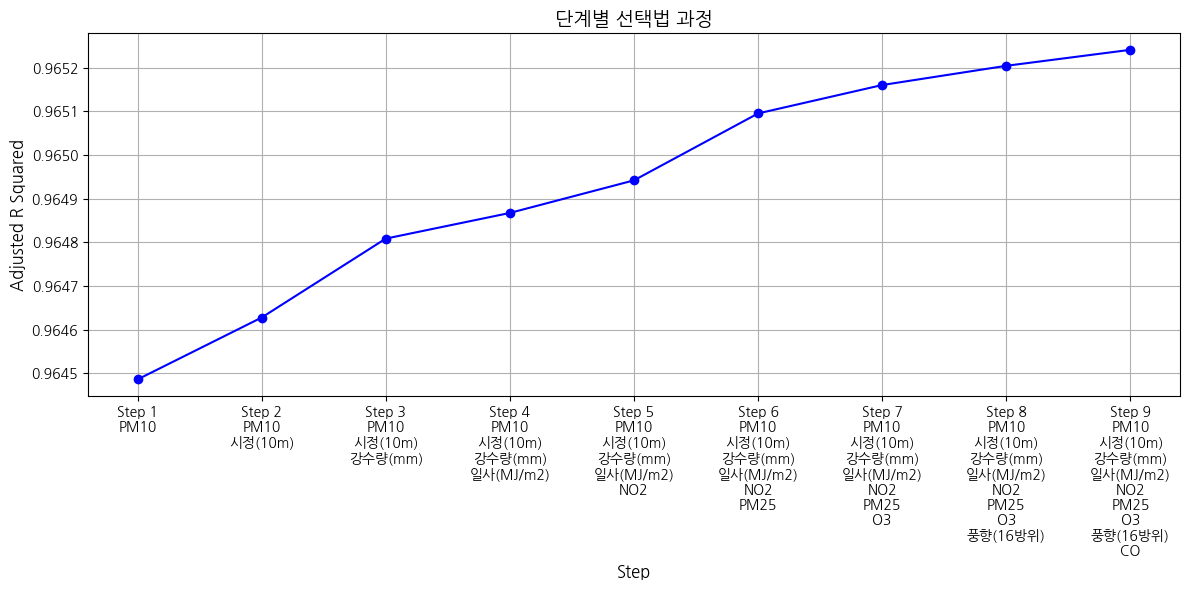

In [107]:
selected_variables_first = stepwise_feature_selection(df_21.iloc[:, :-1], df_21['PM10_1'])

In [108]:
df_21.columns

Index(['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)', '강수량(mm)',
       '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)', '현지기압(hPa)',
       '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)', '전운량(10분위)',
       '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)', '5cm 지중온도(°C)',
       '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)', 'PM10_1'],
      dtype='object')

In [109]:
selected_variables = selected_variables_first.copy()

In [110]:
vif(df_21, selected_variables)

,변수,VIF
1,PM10,1.954198
2,시정(10m),1.661030
3,강수량(mm),1.132786
4,일사(MJ/m2),1.282947
5,NO2,5.045086
6,PM25,3.835978
7,O3,2.080808
8,풍향(16방위),1.109164
9,CO,5.160519


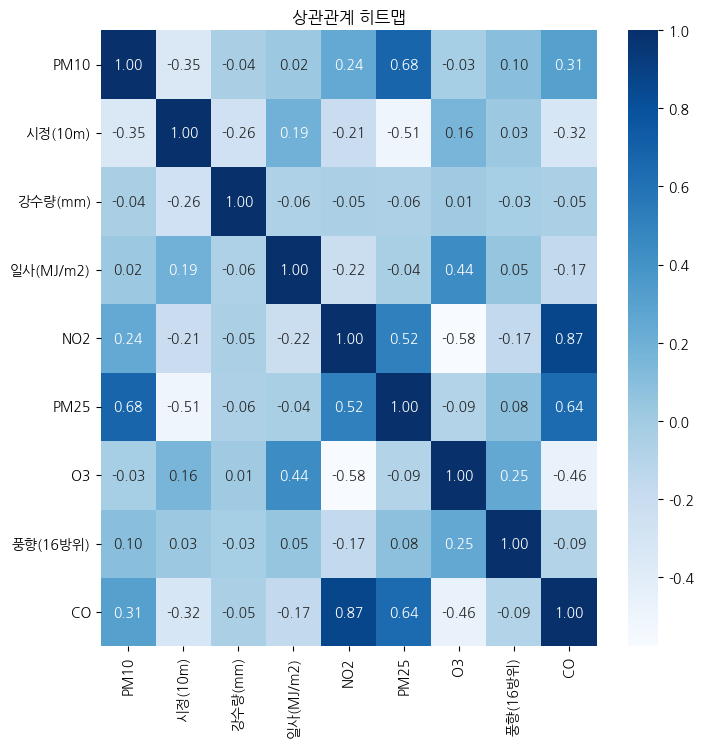

In [111]:
df_21_corr = df_21[selected_variables].corr()
plt.figure(figsize=(8, 8))
sns.heatmap(df_21_corr, annot=True, cmap='Blues', fmt=".2f")
plt.title("상관관계 히트맵")
plt.show()

In [112]:
X_train = df_21[selected_variables].values
X_test = df_22[selected_variables].values

y_train = df_21['PM10_1'].values
y_test = df_22['PM10_1'].values

In [113]:
# 스케일링
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

#### [2-2-1] 랜덤포레스트

In [114]:
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

In [115]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

6.184629168456891


In [116]:
r2_score(y_test, y_pred)

0.9307562897625403

#### [2-2-2] XGMRegressor

In [117]:
xgb_model = XGBRegressor(random_state=42)
xgb_model.fit(X_train, y_train)

y_pred = xgb_model.predict(X_test)

In [118]:
print(np.sqrt(mse(y_test, y_pred)))

6.2329838902527435


In [119]:
r2_score(y_test, y_pred)

0.9296692885879795

#### [2-2-3] LightGBM

In [120]:
lgbm_model = LGBMRegressor(random_state=42)
lgbm_model.fit(X_train, y_train)

y_pred = lgbm_model.predict(X_test)


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000373 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1106
[LightGBM] [Info] Number of data points in the train set: 8758, number of used features: 9
[LightGBM] [Info] Start training from score 38.787965


In [121]:
print(np.sqrt(mse(y_test, y_pred)))

5.709161003003303


In [122]:
r2_score(y_test, y_pred)

0.9409938087089509

# 갑자기 등장한 LSTM

In [123]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from sklearn.preprocessing import MinMaxScaler
# from sklearn.metrics import mean_squared_error
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import LSTM, Dense

# # 1. 데이터 준비
# df_21 = df_21.copy()
# df_22 = df_22.copy()

# # 2. PM10만 추출
# train_pm10 = df_21['PM10'].values.reshape(-1, 1)
# test_pm10 = df_22['PM10'].values.reshape(-1, 1)

# # 3. 정규화 (train 기준으로만 fit)
# scaler = MinMaxScaler()
# train_scaled = scaler.fit_transform(train_pm10)

# # 4. 시계열 샘플 생성 함수 (입력 24시간 → 출력 6시간)
# def make_sequence(data, input_len=24, output_len=6):
#     X, y = [], []
#     for i in range(len(data) - input_len - output_len + 1):
#         X.append(data[i:i+input_len])
#         y.append(data[i+input_len:i+input_len+output_len].flatten())  # (6,)
#     return np.array(X), np.array(y)

# X, y = make_sequence(train_scaled, 24, 6)

# # 5. 예측용 입력: 2021년 마지막 24시간
# X_test_input = train_scaled[-24:].reshape(1, 24, 1)

# # 6. 모델 정의
# model = Sequential([
#     LSTM(64, input_shape=(24, 1)),  # 24시간 입력 후 벡터 출력
#     Dense(6)  # 다음 6시간 예측
# ])
# model.compile(optimizer='adam', loss='mse')

# # 7. 모델 훈련
# model.fit(X, y, epochs=20, batch_size=16, verbose=0)

# # 8. 예측 수행
# y_pred_scaled = model.predict(X_test_input)  # shape: (1, 6)
# y_pred = scaler.inverse_transform(y_pred_scaled.reshape(-1, 1))  # shape: (6, 1)

# # 9. 실제값: 2022년 1월 1일 00시 ~ 05시
# y_true = df_22.iloc[0:6]['PM10'].values.reshape(-1, 1)

# # 10. 비교 및 출력
# comparison_df = pd.DataFrame({
#     'Hour': [f'{i:02d}:00' for i in range(6)],
#     'Actual_PM10': y_true.flatten(),
#     'Predicted_PM10': y_pred.flatten()
# })
# print(comparison_df)

# rmse = np.sqrt(mean_squared_error(y_true, y_pred))
# r2 = r2_score(y_true, y_pred)
# mae = mean_absolute_error(y_true, y_pred)
# mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# # 출력
# print(f"RMSE: {rmse:.4f}")
# print(f"R² Score: {r2:.4f}")
# print(f"MAE: {mae:.4f}")
# print(f"MAPE: {mape:.2f}%")

# # 12. 시각화
# plt.figure(figsize=(8, 4))
# plt.plot(comparison_df['Hour'], comparison_df['Actual_PM10'], label='Actual PM10', marker='o')
# plt.plot(comparison_df['Hour'], comparison_df['Predicted_PM10'], label='Predicted PM10', marker='x', linestyle='--')
# plt.title('PM10 Prediction vs Actual (2022-01-01 00~05시)')
# plt.xlabel('Hour')
# plt.ylabel('PM10')
# plt.xticks(rotation=45)
# plt.legend()
# plt.grid(True)
# plt.tight_layout()
# plt.show()


In [124]:
# df_21.columns

In [125]:
# selected_variables

In [126]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from sklearn.preprocessing import MinMaxScaler
# from sklearn.metrics import mean_squared_error, r2_score
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import LSTM, Dense

# # 1. 데이터 복사
# df_21 = df_21.copy()
# df_22 = df_22.copy()

# # 2. 다변량 입력 피처 선택 (PM10은 타겟으로 따로 분리)
# input_features = selected_variables
# target_feature = 'PM10_1'

# # 3. 정규화: 입력과 타겟 따로
# scaler_X = MinMaxScaler()
# scaler_y = MinMaxScaler()

# X_train_raw = df_21[input_features].values
# y_train_raw = df_21[[target_feature]].values

# X_train_scaled = scaler_X.fit_transform(X_train_raw)
# y_train_scaled = scaler_y.fit_transform(y_train_raw)

# # 4. 시계열 샘플 생성 함수 (다변량 입력, 단변량 다시간 출력)
# def make_multivar_sequence(X, y, input_len=24, output_len=6):
#     X_seq, y_seq = [], []
#     for i in range(len(X) - input_len - output_len + 1):
#         X_seq.append(X[i:i+input_len])
#         y_seq.append(y[i+input_len:i+input_len+output_len].flatten())  # (6,)
#     return np.array(X_seq), np.array(y_seq)

# X, y = make_multivar_sequence(X_train_scaled, y_train_scaled, input_len=24, output_len=6)

# # 5. 예측용 입력: 2021년 마지막 24시간
# X_last = scaler_X.transform(df_21[input_features].values)[-24:].reshape(1, 24, len(input_features))

# # 6. 모델 정의
# model = Sequential([
#     LSTM(64, input_shape=(24, len(input_features))),
#     Dense(6)  # 6시간 PM10 예측
# ])
# model.compile(optimizer='adam', loss='mse')

# # 7. 모델 훈련
# model.fit(X, y, epochs=20, batch_size=16, verbose=0)

# # 8. 예측 수행
# y_pred_scaled = model.predict(X_last)  # (1, 6)
# y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1))  # (6, 1)

# # 9. 실제값: 2022년 1월 1일 00시 ~ 05시
# y_true = df_22.iloc[0:6][target_feature].values.reshape(-1, 1)

# # 10. 비교
# comparison_df = pd.DataFrame({
#     'Hour': [f'{i:02d}:00' for i in range(6)],
#     'Actual_PM10': y_true.flatten(),
#     'Predicted_PM10': y_pred.flatten()
# })
# print(comparison_df)

# rmse = np.sqrt(mean_squared_error(y_true, y_pred))
# r2 = r2_score(y_true, y_pred)
# mae = mean_absolute_error(y_true, y_pred)
# mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# # 출력
# print(f"RMSE: {rmse:.4f}")
# print(f"R² Score: {r2:.4f}")
# print(f"MAE: {mae:.4f}")
# print(f"MAPE: {mape:.2f}%")

# # 12. 시각화
# plt.figure(figsize=(8, 4))
# plt.plot(comparison_df['Hour'], comparison_df['Actual_PM10'], label='Actual PM10', marker='o')
# plt.plot(comparison_df['Hour'], comparison_df['Predicted_PM10'], label='Predicted PM10', marker='x', linestyle='--')
# plt.title('다변량 입력 → PM10 6시간 예측 (2022-01-01)')
# plt.xlabel('Hour')
# plt.ylabel('PM10')
# plt.xticks(rotation=45)
# plt.legend()
# plt.grid(True)
# plt.tight_layout()
# plt.show()
